# `GridSearchCV` 를 이용한 회귀 모델 성능 고도화 (교재 p.141)

교재 p.141 실습 — 분류([`cross_validation_gridsearch.ipynb`](./cross_validation_gridsearch.ipynb))와 같은 방법을 **회귀**(보스턴 집값, [Day 024](../../2026-10-13/) 의 회귀 트리)에 적용했습니다.

> 수업 필기에는 회귀 실습 코드가 없어서 교재 순서에 맞춰 새로 작성했습니다. 데이터 `house_price.csv` 는 Day 021 · 024 와 같은 보스턴 집값(506행 × 14열, 정답 `medv` = 집값, 단위 천 달러).

In [1]:
# 그래프 한글 폰트 설정 (운영체제별)
import platform
import matplotlib.pyplot as plt

if platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import root_mean_squared_error

df = pd.read_csv('./house_price.csv')
X_data = df.drop(columns=['medv'])
y_data = df['medv']

# Day 024 와 같은 분할 (평가용 25%)
X_train, X_test, y_train, y_test = train_test_split(X_data, y_data, test_size=0.25, random_state=0)
print("학습용 :", X_train.shape, " 평가용 :", X_test.shape)

dt0 = DecisionTreeRegressor(random_state=0).fit(X_train, y_train)
print("기본값 트리 평가용 RMSE :", round(root_mean_squared_error(y_test, dt0.predict(X_test)), 2), "(Day 024 와 같음)")

학습용 : (379, 13)  평가용 : (127, 13)
기본값 트리 평가용 RMSE : 5.41 (Day 024 와 같음)


## 1. 회귀의 `scoring` — 왜 음수(neg_)인가

`GridSearchCV` 는 **점수가 클수록 좋다**고 보고 최댓값을 고른다. 그런데 RMSE 는 **작을수록** 좋다 → 부호를 바꾼 **`'neg_root_mean_squared_error'`** 를 쓴다(−3.9 > −5.2).

| 분류 | 회귀 |
|---|---|
| `'accuracy'`, `'f1'`, `'roc_auc'` | `'neg_root_mean_squared_error'`, `'neg_mean_absolute_error'`, `'r2'` |

In [3]:
from sklearn.model_selection import GridSearchCV

params = {
    'max_depth': [2, 3, 4, 5, 6, 7, 8, 9, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5, 6, 8, 10],
}

grid_reg = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=0),
    param_grid=params,
    scoring='neg_root_mean_squared_error',   # RMSE 의 음수 → 클수록(0 에 가까울수록) 좋음
    cv=5,
)
grid_reg.fit(X_train, y_train)

print("최적 하이퍼파라미터 :", grid_reg.best_params_)
print("검증 평균 RMSE     :", round(-grid_reg.best_score_, 2))      # 부호를 다시 뒤집어서 읽는다

best_reg = grid_reg.best_estimator_
print("평가용 RMSE        :", round(root_mean_squared_error(y_test, best_reg.predict(X_test)), 2))

최적 하이퍼파라미터 : {'max_depth': 8, 'min_samples_leaf': 5}
검증 평균 RMSE     : 3.85
평가용 RMSE        : 5.4


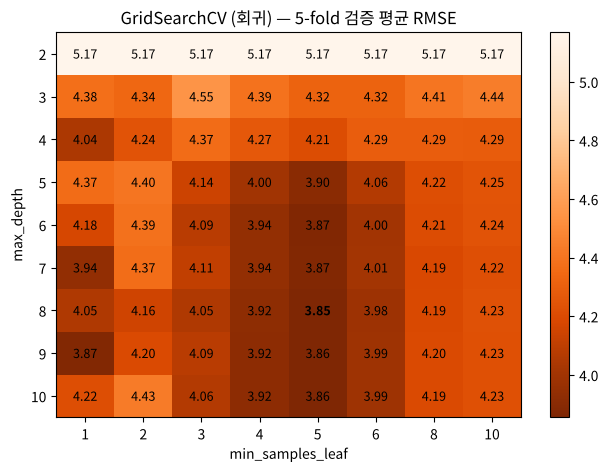

In [4]:
# 검증 평균 RMSE 표 (작을수록 좋음)
table = -pd.DataFrame(grid_reg.cv_results_).pivot(
    index='param_max_depth', columns='param_min_samples_leaf', values='mean_test_score')

fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(table, cmap='Oranges_r', aspect='auto')
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.iloc[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=9,
                weight='bold' if v == table.values.min() else 'normal')
ax.set_xticks(range(table.shape[1]), table.columns)
ax.set_yticks(range(table.shape[0]), table.index)
ax.set_xlabel('min_samples_leaf'); ax.set_ylabel('max_depth')
ax.set_title('GridSearchCV (회귀) — 5-fold 검증 평균 RMSE')
plt.colorbar(im, ax=ax)
plt.show()

결과가 **이상하다**: 검증 평균 RMSE 는 **3.85** 인데 평가용 RMSE 는 **5.40** — 기본값 트리(5.41)와 거의 같다. 튜닝이 소용없었던 걸까?

- 학습용이 **379개**뿐이라 fold 하나가 76개 — 검증 점수 자체가 많이 흔들린다(위 표에서 이웃한 칸끼리도 3.9 ~ 4.4 로 들쭉날쭉).
- 평가용 127개도 **한 번 나눈 결과** — 이번 분할이 유난히 맞히기 어려운 집들일 수 있다([Day 024](../../2026-10-13/) 에서 분할만 바꿔도 RMSE 가 크게 흔들렸다).

한 번의 분할로는 판단할 수 없으니, **분할을 20번 바꿔** "기본값 트리 vs GridSearchCV 로 고른 트리" 를 비교해 보자.

In [5]:
rows = []
for rs in range(20):
    a, b, c, d = train_test_split(X_data, y_data, test_size=0.25, random_state=rs)
    default_rmse = root_mean_squared_error(d, DecisionTreeRegressor(random_state=0).fit(a, c).predict(b))
    g = GridSearchCV(DecisionTreeRegressor(random_state=0), params,
                     scoring='neg_root_mean_squared_error', cv=5).fit(a, c)
    rows.append({'분할': rs, '기본값': default_rmse, 'GridSearchCV': root_mean_squared_error(d, g.predict(b)),
                 'max_depth': g.best_params_['max_depth'], 'min_samples_leaf': g.best_params_['min_samples_leaf']})

split_df = pd.DataFrame(rows)
print("평균 RMSE :", split_df[['기본값', 'GridSearchCV']].mean().round(2).to_dict())
print("GridSearchCV 가 더 좋았던 분할 :", (split_df['GridSearchCV'] < split_df['기본값']).sum(), "/ 20")
split_df.round(2)

평균 RMSE : {'기본값': 4.82, 'GridSearchCV': 4.64}
GridSearchCV 가 더 좋았던 분할 : 13 / 20


,분할,기본값,GridSearchCV,max_depth,min_samples_leaf
0,0,5.41,5.40,8,5
1,1,3.95,3.61,5,3
2,2,5.40,4.98,7,2
3,3,4.00,3.89,4,3
4,4,5.42,5.06,5,2
5,5,6.29,6.16,9,1
6,6,6.38,5.06,6,5
7,7,5.27,4.66,6,5
8,8,4.31,4.07,5,2
9,9,5.49,4.57,5,3


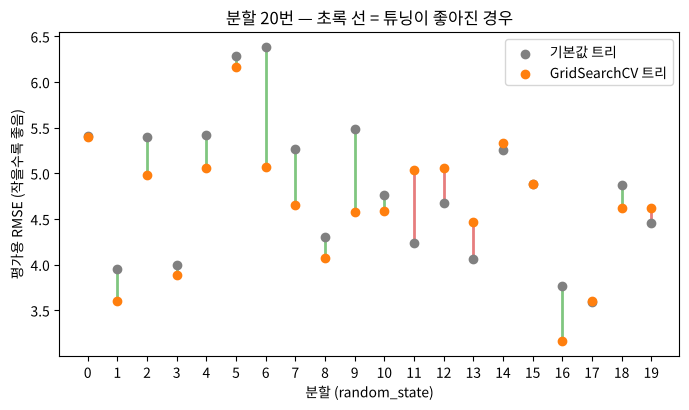

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for _, r in split_df.iterrows():
    better = r['GridSearchCV'] < r['기본값']
    ax.plot([r['분할'], r['분할']], [r['기본값'], r['GridSearchCV']],
            color='tab:green' if better else 'tab:red', lw=2, alpha=0.6)
ax.scatter(split_df['분할'], split_df['기본값'], color='gray', label='기본값 트리', zorder=3)
ax.scatter(split_df['분할'], split_df['GridSearchCV'], color='tab:orange', label='GridSearchCV 트리', zorder=3)
ax.set_xlabel('분할 (random_state)'); ax.set_ylabel('평가용 RMSE (작을수록 좋음)')
ax.set_xticks(range(20)); ax.legend()
ax.set_title('분할 20번 — 초록 선 = 튜닝이 좋아진 경우')
plt.show()

![분할 20번 비교](./images/06_regression_splits.png)

| | 기본값 트리 | GridSearchCV 트리 |
|---|---|---|
| 평가용 RMSE 평균 (분할 20번) | 4.82 | **4.64** |
| 더 좋았던 분할 | — | **13 / 20** |

- **평균적으로는** 튜닝이 효과가 있다(4.82 → 4.64). 하지만 분할에 따라 오히려 나빠지기도 한다 — 데이터가 작으면 검증 점수도 흔들리기 때문.
- 고른 `max_depth` 도 분할마다 **4 ~ 10** 으로 바뀐다 → 작은 데이터에서 "최적 하이퍼파라미터"는 하나로 딱 정해지지 않는다.
- 그래서 한 번의 평가용 점수로 "튜닝이 소용없다/있다" 를 판단하면 안 된다. 이것이 교재 p.135 의 **"지양해야 할 평가 방법"** 의 진짜 의미.

| 분류 (당뇨병 56,553명) | 회귀 (보스턴 379개) |
|---|---|
| 검증 0.7419 ≈ 평가 0.7411 — **믿을 만함** | 검증 3.85 vs 평가 5.40 — **차이 큼** |
| 데이터가 크면 검증 점수가 안정적 | 데이터가 작으면 반복 평가 · 앙상블이 필요 |